# 05. Node Classification

This notebook answers RQ1 with five fixed stratified splits. It compares a majority baseline, neighbor majority, logistic regression on graph features, and logistic regression on graph plus community features.


In [1]:
from pathlib import Path
import os
import sys
import warnings

import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display


def find_project_root(start: Path) -> Path:
    """Find the repository root whether Jupyter starts there or in notebooks/."""
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root.")


ROOT = find_project_root(Path.cwd())
os.chdir(ROOT)
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
print(f"Project root: {ROOT}")


Project root: C:\Users\Jimi\Desktop\github-social-network


## Split, preprocessing, and evaluation logic

The implementation in `src/modeling.py` follows this protocol for every seed:

```text
outer_train, test = stratified_split(all_labeled_nodes, 70/30)
inner_train, validation = stratified_split(outer_train, 80/20)

build neighbor-label and community-label features from inner_train labels only
fit one-hot column layout, StandardScaler, and LogisticRegression on inner_train only
choose the probability threshold using validation F1 only
evaluate once on the untouched test labels
```

For the main repeated model comparison, each scaler and classifier is fitted on that split's training matrix and only transformed on the test matrix. Louvain community membership is label-free. Test labels are never used to create graph or community features.


### Production implementation: splits and baseline classifiers

This code is the first part of src/modeling.py: it creates the stratified train/test split and implements the majority-class and neighbor-majority baselines. It receives node IDs, labels, the graph, and optional threshold or fallback settings, and returns aligned predictions plus the learned global proportion or threshold metadata. The neighbor method uses only training labels, so its fallback behavior for nodes with no labeled neighbors is part of the leakage-safe baseline rather than a hidden preprocessing step.


In [2]:
from typing import Dict, Iterable, Sequence, Tuple

import networkx as nx
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from community_analysis import (
    add_community_features,
    detect_louvain_communities,
    summarize_communities,
)


COMMUNITY_ID_COLUMN = "community_id"


def prepare_train_test_split(
    labels_df: pd.DataFrame,
    test_size: float = 0.3,
    random_state: int = 42,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Create a stratified train/test split over labeled node IDs."""
    if "id" not in labels_df.columns or "label" not in labels_df.columns:
        raise ValueError("labels_df must contain 'id' and 'label' columns.")

    nodes = labels_df["id"].to_numpy(dtype=np.int64)
    labels = labels_df["label"].to_numpy(dtype=np.int64)

    train_nodes, test_nodes, y_train, y_test = train_test_split(
        nodes,
        labels,
        test_size=test_size,
        random_state=random_state,
        stratify=labels,
    )

    return train_nodes, test_nodes, y_train, y_test


def majority_class_baseline(y_train: Iterable[int], y_test: Iterable[int]) -> Tuple[np.ndarray, np.ndarray]:
    """
    Predict the train-set majority class for all test nodes.

    Returns:
        y_pred: hard predictions
        y_score: constant ML probability (train positive-class prior)
    """
    y_train_arr = np.asarray(list(y_train), dtype=np.int64)
    y_test_arr = np.asarray(list(y_test), dtype=np.int64)

    class_counts = np.bincount(y_train_arr, minlength=2)
    majority_label = int(np.argmax(class_counts))
    ml_prior = float(np.mean(y_train_arr))

    y_pred = np.full(shape=y_test_arr.shape, fill_value=majority_label, dtype=np.int64)
    y_score = np.full(shape=y_test_arr.shape, fill_value=ml_prior, dtype=np.float64)

    return y_pred, y_score


def neighbor_majority_classifier(
    G: nx.Graph,
    labels_dict: Dict[int, int],
    train_nodes: Iterable[int],
    test_nodes: Iterable[int],
    default_label: int,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Predict each test node from the majority label among its train-labeled neighbors.

    The ML score is the fraction of known ML neighbors.
    If no known neighbors exist, prediction falls back to default_label and score to train ML prior.
    """
    train_set = {int(node) for node in train_nodes}
    test_list = [int(node) for node in test_nodes]
    train_label_dict = {node: int(labels_dict[node]) for node in train_set if node in labels_dict}
    train_ml_prior = float(np.mean(list(train_label_dict.values()))) if train_label_dict else 0.5

    y_pred = []
    y_score = []

    for node in test_list:
        known_web = 0
        known_ml = 0

        if node in G:
            for neighbor in G.neighbors(node):
                if neighbor not in train_set:
                    continue
                neighbor_label = train_label_dict.get(int(neighbor))
                if neighbor_label == 0:
                    known_web += 1
                elif neighbor_label == 1:
                    known_ml += 1

        known_total = known_web + known_ml
        if known_total == 0:
            pred_label = int(default_label)
            ml_score = train_ml_prior
        else:
            ml_score = known_ml / known_total
            if known_ml > known_web:
                pred_label = 1
            elif known_web > known_ml:
                pred_label = 0
            else:
                pred_label = int(default_label)

        y_pred.append(pred_label)
        y_score.append(ml_score)

    return np.asarray(y_pred, dtype=np.int64), np.asarray(y_score, dtype=np.float64)



### Production implementation: leakage-safe graph and community features

This block copies the feature-construction portion of src/modeling.py. It receives the graph, the requested nodes, and training-node labels, then returns degree, clustering, centrality, labeled-neighbor, and community-composition features aligned by node ID. The merge and matrix helpers preserve column alignment and sanitize infinities or missing values before modeling, which is necessary for reproducible training across splits.


In [3]:
def extract_graph_neighbor_features(
    G: nx.Graph,
    labels_dict: Dict[int, int],
    train_nodes: Iterable[int],
    nodes: Iterable[int],
) -> pd.DataFrame:
    """
    Build graph-only features for given nodes.

    Label-based neighborhood features use only labels of train_nodes.
    """
    train_set = {int(node) for node in train_nodes}
    train_label_dict = {node: int(labels_dict[node]) for node in train_set if node in labels_dict}
    nodes_list = [int(node) for node in nodes]

    # Cache expensive structure-only scores to speed repeated experiments.
    if "_pagerank_cache" not in G.graph:
        G.graph["_pagerank_cache"] = nx.pagerank(G)
    if "_clustering_cache" not in G.graph:
        G.graph["_clustering_cache"] = nx.clustering(G)
    if "_core_number_cache" not in G.graph:
        G.graph["_core_number_cache"] = nx.core_number(G)
    
    # --- Fast sample-based approximation of Betweenness Centrality ---
    if "_approx_betweenness_cache" not in G.graph:
        G.graph["_approx_betweenness_cache"] = nx.betweenness_centrality(G, k=100, seed=42)

    # HITS hub and authority scores coincide on an undirected graph.  Keep one
    # score only so the feature matrix does not contain a known duplicate.
    if "_hits_cache" not in G.graph:
        try:
            hubs, _ = nx.hits(G, max_iter=800)
        except nx.PowerIterationFailedConvergence:
            hubs = {}
        G.graph["_hits_cache"] = True
        G.graph["_hubs_cache"] = hubs
        
    if "_triangles_cache" not in G.graph:
        G.graph["_triangles_cache"] = nx.triangles(G)

    pagerank_scores = G.graph["_pagerank_cache"]
    clustering_scores = G.graph["_clustering_cache"]
    core_numbers = G.graph["_core_number_cache"]
    approx_betweenness = G.graph["_approx_betweenness_cache"]
    hubs_scores = G.graph["_hubs_cache"]
    triangles_counts = G.graph["_triangles_cache"]

    rows = []
    for node in nodes_list:
        degree = int(G.degree(node)) if node in G else 0

        known_web = 0
        known_ml = 0
        if node in G:
            for neighbor in G.neighbors(node):
                if neighbor not in train_set:
                    continue
                neighbor_label = train_label_dict.get(int(neighbor))
                if neighbor_label == 0:
                    known_web += 1
                elif neighbor_label == 1:
                    known_ml += 1

        known_neighbors_count = known_web + known_ml
        if known_neighbors_count > 0:
            ml_neighbor_ratio = known_ml / known_neighbors_count
            web_neighbor_ratio = known_web / known_neighbors_count
        else:
            ml_neighbor_ratio = 0.0
            web_neighbor_ratio = 0.0

        rows.append(
            {
                "node_id": node,
                "degree": degree,
                "known_neighbors_count": known_neighbors_count,
                "known_web_neighbors": known_web,
                "known_ml_neighbors": known_ml,
                "ml_neighbor_ratio": ml_neighbor_ratio,
                "web_neighbor_ratio": web_neighbor_ratio,
                "neighbor_label_gap": known_ml - known_web,
                "clustering_coefficient": float(clustering_scores.get(node, 0.0)),
                "pagerank": float(pagerank_scores.get(node, 0.0)),
                "core_number": int(core_numbers.get(node, 0)),
                "approx_betweenness": float(approx_betweenness.get(node, 0.0)),
                "hits_hub_score": float(hubs_scores.get(node, 0.0)),
                "triangles": int(triangles_counts.get(node, 0)),
            }
        )

    return pd.DataFrame(rows)


def _merge_node_feature_frames(
    base_features_df: pd.DataFrame,
    extra_features_df: pd.DataFrame,
) -> pd.DataFrame:
    """Merge two feature frames on node_id with a clean column order."""
    merged = base_features_df.merge(extra_features_df, on="node_id", how="inner")
    return merged


def _prepare_feature_matrix(
    feature_df: pd.DataFrame,
    fit_columns: Sequence[str] | None = None,
) -> pd.DataFrame:
    """
    Remove non-feature identifiers prior to model fitting.

    Currently we drop:
    - node_id

    community_id is categorical. It is one-hot encoded instead of being
    interpreted as an ordinal numeric value.
    """
    x_df = feature_df.copy()
    if "node_id" in x_df.columns:
        x_df = x_df.drop(columns=["node_id"])

    if COMMUNITY_ID_COLUMN in x_df.columns:
        x_df[COMMUNITY_ID_COLUMN] = x_df[COMMUNITY_ID_COLUMN].astype("category")
        x_df = pd.get_dummies(
            x_df,
            columns=[COMMUNITY_ID_COLUMN],
            prefix="community",
            dtype=float,
        )

    if fit_columns is not None:
        x_df = x_df.reindex(columns=list(fit_columns), fill_value=0.0)

    return x_df



### Production implementation: logistic regression, metrics, and threshold selection

This section contains the production training, prediction, metric, threshold-sweep, and validation-selection functions from src/modeling.py. It accepts feature frames and labels, fits a scaled balanced logistic-regression pipeline, and returns predictions, probabilities, metric dictionaries, or a validation-selected threshold. The exact candidate thresholds, tie-breaking order, zero-division behavior, and confusion-matrix outputs are retained because these choices determine every reported classification score.


In [4]:
def train_logistic_regression_graph_features(
    X_train: pd.DataFrame,
    y_train: Iterable[int],
    X_test: pd.DataFrame,
) -> Tuple[Pipeline, np.ndarray, np.ndarray]:
    """Train Logistic Regression over network-only features via a scaling pipeline."""
    x_train_df = _prepare_feature_matrix(X_train)
    x_test_df = _prepare_feature_matrix(X_test, fit_columns=x_train_df.columns)

    model = Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            # --- class_weight="balanced" to handle the class imbalance ---
            ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
        ]
    )
    model.fit(x_train_df, np.asarray(list(y_train), dtype=np.int64))
    model.feature_columns_ = list(x_train_df.columns)

    y_pred = model.predict(x_test_df)
    y_score = model.predict_proba(x_test_df)[:, 1]

    return model, y_pred.astype(np.int64), y_score.astype(np.float64)


def predict_logistic_regression_graph_features(
    model: Pipeline,
    X: pd.DataFrame,
) -> np.ndarray:
    """Predict ML probabilities with the same feature columns used during training."""
    feature_columns = getattr(model, "feature_columns_", None)
    if feature_columns is None:
        raise ValueError("Model is missing feature_columns_. Train it with train_logistic_regression_graph_features.")

    x_df = _prepare_feature_matrix(X, fit_columns=feature_columns)
    return model.predict_proba(x_df)[:, 1].astype(np.float64)


def evaluate_predictions(
    y_true: Iterable[int],
    y_pred: Iterable[int],
    y_score: Iterable[float] | None = None,
) -> Dict[str, float]:
    """Compute classification metrics and confusion-matrix entries."""
    y_true_arr = np.asarray(list(y_true), dtype=np.int64)
    y_pred_arr = np.asarray(list(y_pred), dtype=np.int64)

    cm = confusion_matrix(y_true_arr, y_pred_arr, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "accuracy": float(accuracy_score(y_true_arr, y_pred_arr)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true_arr, y_pred_arr)),
        "precision": float(precision_score(y_true_arr, y_pred_arr, zero_division=0)),
        "recall": float(recall_score(y_true_arr, y_pred_arr, zero_division=0)),
        "f1": float(f1_score(y_true_arr, y_pred_arr, zero_division=0)),
        "macro_f1": float(f1_score(y_true_arr, y_pred_arr, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true_arr, y_pred_arr, average="weighted", zero_division=0)),
        "roc_auc": float("nan"),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

    if y_score is not None:
        y_score_arr = np.asarray(list(y_score), dtype=np.float64)
        try:
            metrics["roc_auc"] = float(roc_auc_score(y_true_arr, y_score_arr))
        except ValueError:
            metrics["roc_auc"] = float("nan")

    return metrics


def evaluate_thresholds(
    y_true: Iterable[int],
    y_score: Iterable[float],
    thresholds: Sequence[float] | None = None,
) -> pd.DataFrame:
    """Evaluate binary predictions across multiple probability thresholds."""
    y_true_arr = np.asarray(list(y_true), dtype=np.int64)
    y_score_arr = np.asarray(list(y_score), dtype=np.float64)

    if y_true_arr.shape[0] != y_score_arr.shape[0]:
        raise ValueError("y_true and y_score must have the same length.")

    if thresholds is None:
        threshold_values = np.round(np.arange(0.05, 0.951, 0.05), 2)
    else:
        threshold_values = np.asarray(list(thresholds), dtype=np.float64)
        if threshold_values.size == 0:
            raise ValueError("thresholds must not be empty.")

    rows = []
    for threshold in threshold_values:
        threshold_float = float(threshold)
        if threshold_float < 0.0 or threshold_float > 1.0:
            raise ValueError("All thresholds must be in [0.0, 1.0].")

        y_pred_arr = (y_score_arr >= threshold_float).astype(np.int64)
        cm = confusion_matrix(y_true_arr, y_pred_arr, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        specificity = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0

        rows.append(
            {
                "threshold": threshold_float,
                "accuracy": float(accuracy_score(y_true_arr, y_pred_arr)),
                "balanced_accuracy": float(balanced_accuracy_score(y_true_arr, y_pred_arr)),
                "precision": float(precision_score(y_true_arr, y_pred_arr, zero_division=0)),
                "recall": float(recall_score(y_true_arr, y_pred_arr, zero_division=0)),
                "f1": float(f1_score(y_true_arr, y_pred_arr, zero_division=0)),
                "macro_f1": float(f1_score(y_true_arr, y_pred_arr, average="macro", zero_division=0)),
                "weighted_f1": float(f1_score(y_true_arr, y_pred_arr, average="weighted", zero_division=0)),
                "specificity": specificity,
                "tn": int(tn),
                "fp": int(fp),
                "fn": int(fn),
                "tp": int(tp),
            }
        )

    return pd.DataFrame(rows).sort_values("threshold").reset_index(drop=True)


def select_best_threshold(
    threshold_results_df: pd.DataFrame,
    metric: str = "f1",
) -> Tuple[float, pd.Series]:
    """Return the threshold row with the highest value for the selected metric."""
    if threshold_results_df.empty:
        raise ValueError("threshold_results_df must not be empty.")
    if "threshold" not in threshold_results_df.columns:
        raise ValueError("threshold_results_df must include a 'threshold' column.")
    if metric not in threshold_results_df.columns:
        raise ValueError(f"metric '{metric}' was not found in threshold_results_df.")

    ranking_df = threshold_results_df.sort_values(
        by=[metric, "threshold"],
        ascending=[False, True],
    )
    best_row = ranking_df.iloc[0].copy()
    best_threshold = float(best_row["threshold"])
    return best_threshold, best_row



### Production implementation: repeated validation-only threshold tuning

This block reproduces the repeated threshold-tuning experiment and its summary function. For each random state it creates a held-out test set and a separate validation subset, constructs leakage-safe features, tunes thresholds on validation data only, and evaluates both default and tuned decisions on the untouched test data. It returns row-level experiment records and an aggregated DataFrame, directly supporting the comparison between fixed and validation-selected classification thresholds.


In [5]:
def run_repeated_threshold_tuning(
    G: nx.Graph,
    labels_df: pd.DataFrame,
    partition: Dict[int, int],
    community_summary_df: pd.DataFrame,
    random_states: Sequence[int] = (42, 7, 21, 84, 123),
    test_size: float = 0.3,
    validation_size: float = 0.2,
    threshold_metric: str = "f1",
) -> pd.DataFrame:
    """
    Repeat threshold tuning across multiple train/test splits without test leakage.

    Per split:
    1) Split labeled nodes into train/test
    2) Split train into train_inner/validation
    3) Train Graph+Community Logistic Regression on train_inner only
    4) Choose threshold on validation only
    5) Evaluate on test using threshold=0.5 and the tuned threshold
    """
    if "id" not in labels_df.columns or "label" not in labels_df.columns:
        raise ValueError("labels_df must contain 'id' and 'label' columns.")
    if validation_size <= 0 or validation_size >= 1:
        raise ValueError("validation_size must be in (0, 1).")

    labels_dict = dict(zip(labels_df["id"].astype(int), labels_df["label"].astype(int)))
    results_rows = []

    for run_idx, random_state in enumerate(list(random_states), start=1):
        train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
            labels_df=labels_df,
            test_size=test_size,
            random_state=int(random_state),
        )

        train_inner_nodes, val_nodes, y_train_inner, y_val = train_test_split(
            train_nodes,
            y_train,
            test_size=validation_size,
            random_state=int(random_state),
            stratify=y_train,
        )

        train_inner_nodes = np.asarray(train_inner_nodes, dtype=np.int64)
        val_nodes = np.asarray(val_nodes, dtype=np.int64)
        y_train_inner = np.asarray(y_train_inner, dtype=np.int64)
        y_val = np.asarray(y_val, dtype=np.int64)
        train_inner_labels = {
            int(node): int(labels_dict[int(node)]) for node in train_inner_nodes
        }

        nodes_for_features = list(train_inner_nodes) + list(val_nodes) + list(test_nodes)

        graph_features_df = extract_graph_neighbor_features(
            G=G,
            labels_dict=train_inner_labels,
            train_nodes=train_inner_nodes,
            nodes=nodes_for_features,
        ).drop_duplicates(subset=["node_id"])

        community_features_df = add_community_features(
            G=G,
            labels_dict=train_inner_labels,
            train_nodes=train_inner_nodes,
            nodes=nodes_for_features,
            partition=partition,
        ).drop_duplicates(subset=["node_id"])

        combined_features_df = _merge_node_feature_frames(graph_features_df, community_features_df)
        combined_features_indexed = combined_features_df.set_index("node_id")

        X_train_inner = combined_features_indexed.reindex(train_inner_nodes).reset_index()
        X_val = combined_features_indexed.reindex(val_nodes).reset_index()
        X_test = combined_features_indexed.reindex(test_nodes).reset_index()

        model, _, y_score_val = train_logistic_regression_graph_features(
            X_train=X_train_inner,
            y_train=y_train_inner,
            X_test=X_val,
        )

        threshold_results_df = evaluate_thresholds(y_true=y_val, y_score=y_score_val)
        tuned_threshold, _ = select_best_threshold(
            threshold_results_df=threshold_results_df,
            metric=threshold_metric,
        )

        y_score_test = predict_logistic_regression_graph_features(model, X_test)

        for evaluation_type, threshold in (
            ("default_threshold_0.5", 0.5),
            ("tuned_threshold_validation_f1", float(tuned_threshold)),
        ):
            y_pred_test = (y_score_test >= float(threshold)).astype(np.int64)
            metrics = evaluate_predictions(y_test, y_pred_test, y_score=y_score_test)

            tn = int(metrics["tn"])
            fp = int(metrics["fp"])
            specificity = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0

            results_rows.append(
                {
                    "run": int(run_idx),
                    "random_state": int(random_state),
                    "selected_threshold": float(threshold),
                    "evaluation_type": evaluation_type,
                    "accuracy": float(metrics["accuracy"]),
                    "balanced_accuracy": float(metrics["balanced_accuracy"]),
                    "precision": float(metrics["precision"]),
                    "recall": float(metrics["recall"]),
                    "f1": float(metrics["f1"]),
                    "macro_f1": float(metrics["macro_f1"]),
                    "weighted_f1": float(metrics["weighted_f1"]),
                    "roc_auc": float(metrics["roc_auc"]),
                    "specificity": specificity,
                    "tn": tn,
                    "fp": fp,
                    "fn": int(metrics["fn"]),
                    "tp": int(metrics["tp"]),
                }
            )

    return pd.DataFrame(results_rows)


def summarize_threshold_tuning_results(results_df: pd.DataFrame) -> pd.DataFrame:
    """Summarize repeated threshold-tuning results by evaluation type (mean/std)."""
    required_cols = {
        "evaluation_type",
        "selected_threshold",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "macro_f1",
        "weighted_f1",
        "roc_auc",
        "specificity",
    }
    missing_cols = required_cols - set(results_df.columns)
    if missing_cols:
        raise ValueError(f"results_df is missing required columns: {sorted(missing_cols)}")

    summary_df = (
        results_df.groupby("evaluation_type", as_index=False)
        .agg(
            selected_threshold_mean=("selected_threshold", "mean"),
            selected_threshold_std=("selected_threshold", "std"),
            accuracy_mean=("accuracy", "mean"),
            accuracy_std=("accuracy", "std"),
            balanced_accuracy_mean=("balanced_accuracy", "mean"),
            balanced_accuracy_std=("balanced_accuracy", "std"),
            precision_mean=("precision", "mean"),
            precision_std=("precision", "std"),
            recall_mean=("recall", "mean"),
            recall_std=("recall", "std"),
            f1_mean=("f1", "mean"),
            f1_std=("f1", "std"),
            macro_f1_mean=("macro_f1", "mean"),
            macro_f1_std=("macro_f1", "std"),
            weighted_f1_mean=("weighted_f1", "mean"),
            weighted_f1_std=("weighted_f1", "std"),
            roc_auc_mean=("roc_auc", "mean"),
            roc_auc_std=("roc_auc", "std"),
            specificity_mean=("specificity", "mean"),
            specificity_std=("specificity", "std"),
        )
        .rename(
            columns={
                "evaluation_type": "Evaluation Type",
                "selected_threshold_mean": "Selected Threshold Mean",
                "selected_threshold_std": "Selected Threshold Std",
                "accuracy_mean": "Accuracy Mean",
                "accuracy_std": "Accuracy Std",
                "balanced_accuracy_mean": "Balanced Accuracy Mean",
                "balanced_accuracy_std": "Balanced Accuracy Std",
                "precision_mean": "Precision Mean",
                "precision_std": "Precision Std",
                "recall_mean": "Recall Mean",
                "recall_std": "Recall Std",
                "f1_mean": "F1 Mean",
                "f1_std": "F1 Std",
                "macro_f1_mean": "Macro F1 Mean",
                "macro_f1_std": "Macro F1 Std",
                "weighted_f1_mean": "Weighted F1 Mean",
                "weighted_f1_std": "Weighted F1 Std",
                "roc_auc_mean": "ROC-AUC Mean",
                "roc_auc_std": "ROC-AUC Std",
                "specificity_mean": "Specificity Mean",
                "specificity_std": "Specificity Std",
            }
        )
    )

    return summary_df



### Production implementation: repeated model experiments and aggregation

This code runs the full repeated comparison among the majority baseline, neighbor-majority classifier, and graph-feature logistic regression. It receives the graph, labels, community assignments, seed list, and split settings; for every seed it records metrics together with aligned per-node predictions and scores, then summarizes means, standard deviations, and confidence intervals. The loop is the central experimental engine behind the model comparison, so its training-label isolation and result schema are shown without simplification.


In [6]:
def run_repeated_experiments(
    G: nx.Graph,
    labels_df: pd.DataFrame,
    n_runs: int = 5,
    test_size: float = 0.3,
    random_states: Sequence[int] = (42, 7, 21, 84, 123),
) -> pd.DataFrame:
    """
    Run repeated train/test experiments across multiple random splits.

    Models:
    - Majority Baseline
    - Neighbor Majority
    - Logistic Regression - Graph Features Only
    - Logistic Regression - Graph + Community Features
    """
    if "id" not in labels_df.columns or "label" not in labels_df.columns:
        raise ValueError("labels_df must contain 'id' and 'label' columns.")
    if n_runs <= 0:
        raise ValueError("n_runs must be positive.")

    random_states = list(random_states)
    if len(random_states) < n_runs:
        raise ValueError("random_states must include at least n_runs values.")

    selected_states = random_states[:n_runs]
    labels_dict = dict(zip(labels_df["id"].astype(int), labels_df["label"].astype(int)))

    # Louvain depends only on graph structure, so we compute it once.
    partition, _ = detect_louvain_communities(G, random_state=42)
    community_summary_df = summarize_communities(G, labels_dict, partition)

    results_rows = []

    for run_idx, random_state in enumerate(selected_states, start=1):
        train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
            labels_df=labels_df,
            test_size=test_size,
            random_state=int(random_state),
        )
        default_label = int(pd.Series(y_train).mode().iloc[0])
        nodes_for_features = list(train_nodes) + list(test_nodes)
        train_labels = {
            int(node): int(labels_dict[int(node)]) for node in train_nodes
        }

        # 1) Majority baseline
        y_pred_majority, y_score_majority = majority_class_baseline(y_train, y_test)
        metrics_majority = evaluate_predictions(y_test, y_pred_majority, y_score_majority)

        # 2) Neighbor majority
        y_pred_neighbor, y_score_neighbor = neighbor_majority_classifier(
            G=G,
            labels_dict=train_labels,
            train_nodes=train_nodes,
            test_nodes=test_nodes,
            default_label=default_label,
        )
        metrics_neighbor = evaluate_predictions(y_test, y_pred_neighbor, y_score_neighbor)

        # 3) Logistic regression on graph-only features
        graph_features_df = extract_graph_neighbor_features(
            G=G,
            labels_dict=train_labels,
            train_nodes=train_nodes,
            nodes=nodes_for_features,
        ).drop_duplicates(subset=["node_id"])
        graph_features_indexed = graph_features_df.set_index("node_id")

        X_train_graph = graph_features_indexed.reindex(train_nodes).reset_index()
        X_test_graph = graph_features_indexed.reindex(test_nodes).reset_index()

        _, y_pred_logreg_graph, y_score_logreg_graph = train_logistic_regression_graph_features(
            X_train=X_train_graph,
            y_train=y_train,
            X_test=X_test_graph,
        )
        metrics_logreg_graph = evaluate_predictions(y_test, y_pred_logreg_graph, y_score_logreg_graph)

        # 4) Logistic regression on graph + community features
        community_features_df = add_community_features(
            G=G,
            labels_dict=train_labels,
            train_nodes=train_nodes,
            nodes=nodes_for_features,
            partition=partition,
        ).drop_duplicates(subset=["node_id"])

        combined_features_df = _merge_node_feature_frames(graph_features_df, community_features_df)
        combined_features_indexed = combined_features_df.set_index("node_id")

        X_train_combined = combined_features_indexed.reindex(train_nodes).reset_index()
        X_test_combined = combined_features_indexed.reindex(test_nodes).reset_index()

        _, y_pred_logreg_graph_comm, y_score_logreg_graph_comm = train_logistic_regression_graph_features(
            X_train=X_train_combined,
            y_train=y_train,
            X_test=X_test_combined,
        )
        metrics_logreg_graph_comm = evaluate_predictions(
            y_test,
            y_pred_logreg_graph_comm,
            y_score_logreg_graph_comm,
        )

        for model_name, metrics in (
            ("Majority Baseline", metrics_majority),
            ("Neighbor Majority", metrics_neighbor),
            ("Logistic Regression - Graph Features Only", metrics_logreg_graph),
            ("Logistic Regression - Graph + Community Features", metrics_logreg_graph_comm),
        ):
            results_rows.append(
                {
                    "run": run_idx,
                    "random_state": int(random_state),
                    "model": model_name,
                    "accuracy": metrics["accuracy"],
                    "balanced_accuracy": metrics["balanced_accuracy"],
                    "precision": metrics["precision"],
                    "recall": metrics["recall"],
                    "f1": metrics["f1"],
                    "macro_f1": metrics["macro_f1"],
                    "weighted_f1": metrics["weighted_f1"],
                    "roc_auc": metrics["roc_auc"],
                }
            )

    return pd.DataFrame(results_rows)


def summarize_repeated_results(results_df: pd.DataFrame) -> pd.DataFrame:
    """Aggregate mean and standard deviation of metrics per model."""
    required_cols = {
        "model",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "macro_f1",
        "weighted_f1",
        "roc_auc",
    }
    missing_cols = required_cols - set(results_df.columns)
    if missing_cols:
        raise ValueError(f"results_df is missing required columns: {sorted(missing_cols)}")

    summary_df = (
        results_df.groupby("model", as_index=False)
        .agg(
            accuracy_mean=("accuracy", "mean"),
            accuracy_std=("accuracy", "std"),
            balanced_accuracy_mean=("balanced_accuracy", "mean"),
            balanced_accuracy_std=("balanced_accuracy", "std"),
            precision_mean=("precision", "mean"),
            precision_std=("precision", "std"),
            recall_mean=("recall", "mean"),
            recall_std=("recall", "std"),
            f1_mean=("f1", "mean"),
            f1_std=("f1", "std"),
            macro_f1_mean=("macro_f1", "mean"),
            macro_f1_std=("macro_f1", "std"),
            weighted_f1_mean=("weighted_f1", "mean"),
            weighted_f1_std=("weighted_f1", "std"),
            roc_auc_mean=("roc_auc", "mean"),
            roc_auc_std=("roc_auc", "std"),
        )
        .rename(
            columns={
                "model": "Model",
                "accuracy_mean": "Accuracy Mean",
                "accuracy_std": "Accuracy Std",
                "balanced_accuracy_mean": "Balanced Accuracy Mean",
                "balanced_accuracy_std": "Balanced Accuracy Std",
                "precision_mean": "Precision Mean",
                "precision_std": "Precision Std",
                "recall_mean": "Recall Mean",
                "recall_std": "Recall Std",
                "f1_mean": "F1 Mean",
                "f1_std": "F1 Std",
                "macro_f1_mean": "Macro F1 Mean",
                "macro_f1_std": "Macro F1 Std",
                "weighted_f1_mean": "Weighted F1 Mean",
                "weighted_f1_std": "Weighted F1 Std",
                "roc_auc_mean": "ROC-AUC Mean",
                "roc_auc_std": "ROC-AUC Std",
            }
        )
    )

    return summary_df



### Production implementation: subgroup and error analysis

The final modeling block assigns degree groups, evaluates predictions within those groups, relates mistakes to community purity, and counts error types. It receives the graph plus per-node predictions, scores, labels, and community summaries, and returns tidy DataFrames used by the diagnostic tables and plots below. These calculations explain where the classifier succeeds or fails rather than reporting only overall averages.


In [7]:
def assign_degree_group(G: nx.Graph, nodes: Iterable[int]) -> pd.DataFrame:
    """Assign each node to a predefined degree bucket."""
    rows = []
    for node in nodes:
        node_int = int(node)
        degree = int(G.degree(node_int)) if node_int in G else 0

        if degree <= 2:
            group = "degree_0_2"
        elif degree <= 5:
            group = "degree_3_5"
        elif degree <= 10:
            group = "degree_6_10"
        elif degree <= 30:
            group = "degree_11_30"
        else:
            group = "degree_31_plus"

        rows.append({"node_id": node_int, "degree": degree, "degree_group": group})

    return pd.DataFrame(rows)


def evaluate_by_degree_group(
    G: nx.Graph,
    test_nodes: Iterable[int],
    y_true: Iterable[int],
    y_pred: Iterable[int],
) -> pd.DataFrame:
    """Evaluate classification performance across node degree groups."""
    ordered_groups = [
        "degree_0_2",
        "degree_3_5",
        "degree_6_10",
        "degree_11_30",
        "degree_31_plus",
    ]

    degree_df = assign_degree_group(G, test_nodes)
    eval_df = pd.DataFrame(
        {
            "node_id": [int(n) for n in test_nodes],
            "y_true": np.asarray(list(y_true), dtype=np.int64),
            "y_pred": np.asarray(list(y_pred), dtype=np.int64),
        }
    )
    merged_df = eval_df.merge(degree_df[["node_id", "degree_group"]], on="node_id", how="left")

    rows = []
    for group in ordered_groups:
        group_df = merged_df[merged_df["degree_group"] == group]
        count = int(len(group_df))

        if count == 0:
            rows.append(
                {
                    "degree_group": group,
                    "count": 0,
                    "accuracy": np.nan,
                    "balanced_accuracy": np.nan,
                    "precision": np.nan,
                    "recall": np.nan,
                    "f1": np.nan,
                }
            )
            continue

        metrics = evaluate_predictions(group_df["y_true"], group_df["y_pred"], y_score=None)
        rows.append(
            {
                "degree_group": group,
                "count": count,
                "accuracy": metrics["accuracy"],
                    "balanced_accuracy": metrics["balanced_accuracy"],
                    "precision": metrics["precision"],
                    "recall": metrics["recall"],
                    "f1": metrics["f1"],
                    "macro_f1": metrics["macro_f1"],
                    "weighted_f1": metrics["weighted_f1"],
                }
            )

    return pd.DataFrame(rows)


def evaluate_errors_by_community_purity(
    test_nodes: Iterable[int],
    y_true: Iterable[int],
    y_pred: Iterable[int],
    partition: Dict[int, int],
    community_summary_df: pd.DataFrame,
) -> pd.DataFrame:
    """Summarize model error rate by community-purity buckets."""
    purity_map = dict(
        zip(
            community_summary_df["community_id"].astype(int),
            community_summary_df["purity"].astype(float),
        )
    )

    rows = []
    for node, true_label, pred_label in zip(test_nodes, y_true, y_pred):
        community_id = int(partition.get(int(node), -1))
        purity = float(purity_map.get(community_id, 0.0))
        if purity < 0.7:
            purity_group = "mixed_lt_0.70"
        elif purity < 0.85:
            purity_group = "medium_0.70_0.85"
        else:
            purity_group = "pure_0.85_plus"

        rows.append(
            {
                "node_id": int(node),
                "community_id": community_id,
                "community_purity": purity,
                "purity_group": purity_group,
                "y_true": int(true_label),
                "y_pred": int(pred_label),
                "is_error": int(true_label) != int(pred_label),
            }
        )

    details_df = pd.DataFrame(rows)
    ordered_groups = ["mixed_lt_0.70", "medium_0.70_0.85", "pure_0.85_plus"]
    summary_rows = []
    for group in ordered_groups:
        group_df = details_df[details_df["purity_group"] == group]
        count = int(len(group_df))
        errors = int(group_df["is_error"].sum()) if count else 0
        summary_rows.append(
            {
                "purity_group": group,
                "count": count,
                "errors": errors,
                "error_rate": float(errors / count) if count else np.nan,
            }
        )

    return pd.DataFrame(summary_rows)


def summarize_error_types(
    y_true: Iterable[int],
    y_pred: Iterable[int],
) -> pd.DataFrame:
    """Count correct and incorrect predictions by semantic class transition."""
    y_true_arr = np.asarray(list(y_true), dtype=np.int64)
    y_pred_arr = np.asarray(list(y_pred), dtype=np.int64)

    type_map = {
        (0, 0): "Correct Web",
        (1, 1): "Correct ML",
        (0, 1): "Web -> ML",
        (1, 0): "ML -> Web",
    }

    rows = []
    total = len(y_true_arr)
    for pair, label in type_map.items():
        count = int(np.sum((y_true_arr == pair[0]) & (y_pred_arr == pair[1])))
        rows.append(
            {
                "error_type": label,
                "count": count,
                "ratio": float(count / total) if total else 0.0,
            }
        )

    return pd.DataFrame(rows)


The exact shared implementations for plot_community_purity_error_rates and plot_error_type_counts are shown in Notebook 03 under **Production implementation: shared research visualizations**. They are defined there once with the other functions from src/visualization.py; the diagnostic tables produced here are their direct inputs.


In [8]:
from data_loader import load_dataset
from modeling import prepare_train_test_split

G, _, labels_df, _ = load_dataset(ROOT / "data")
train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
    labels_df, test_size=0.30, random_state=SEED
)
split_check = pd.DataFrame([{
    "train_nodes": len(train_nodes),
    "test_nodes": len(test_nodes),
    "train_ml_share": float(np.mean(y_train)),
    "test_ml_share": float(np.mean(y_test)),
    "node_overlap": len(set(train_nodes) & set(test_nodes)),
}])
display(split_check)
assert split_check.loc[0, "node_overlap"] == 0


,train_nodes,test_nodes,train_ml_share,test_ml_share,node_overlap
0,26390,11310,0.258318,0.258355,0


### Production implementation: classification reporting workflow

This cell reproduces src/run_classification.py, including summary-table construction, model and threshold plots, degree-group charts, and the main reporting workflow. It consumes the repeated experiment outputs and writes the exact tables and figures displayed later in the notebook, while its main function coordinates loading, communities, model runs, tuning, and diagnostic analysis. Showing this layer connects the reusable algorithms above to the saved research artifacts and exposes every reporting parameter and column selection.


In [9]:
"""Repeated leakage-safe node classification with course-covered features."""

from pathlib import Path
import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SRC_DIR = ROOT / "src"
PROJECT_DIR = ROOT
sys.path.insert(0, str(SRC_DIR))

from community_analysis import (
    add_community_features,
    detect_louvain_communities,
    summarize_communities,
)
from data_loader import load_dataset
from modeling import (
    evaluate_by_degree_group,
    evaluate_errors_by_community_purity,
    extract_graph_neighbor_features,
    prepare_train_test_split,
    run_repeated_experiments,
    run_repeated_threshold_tuning,
    summarize_error_types,
    train_logistic_regression_graph_features,
)
from visualization import plot_community_purity_error_rates, plot_error_type_counts


SEEDS = (42, 7, 21, 84, 123)
BASE_CLASSIFICATION_MODELS = (
    "Majority Baseline",
    "Neighbor Majority",
    "Logistic Regression - Graph Features Only",
    "Logistic Regression - Graph + Community Features",
)
METRICS = (
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "macro_f1",
    "weighted_f1",
    "roc_auc",
)


def summarize_results(results_df: pd.DataFrame) -> pd.DataFrame:
    """Return one auditable mean/std row per model."""
    summary = results_df.groupby("model", as_index=False)[list(METRICS)].agg(
        ["mean", "std"]
    )
    summary.columns = [
        "model" if column == ("model", "") else f"{column[0]}_{column[1]}"
        for column in summary.columns
    ]
    return summary.sort_values("roc_auc_mean").reset_index(drop=True)


def summarize_thresholds(results_df: pd.DataFrame) -> pd.DataFrame:
    """Summarize validation-only threshold selection across seeds."""
    metrics = [
        "selected_threshold",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "macro_f1",
        "weighted_f1",
        "roc_auc",
        "specificity",
    ]
    summary = results_df.groupby("evaluation_type", as_index=False)[metrics].agg(
        ["mean", "std"]
    )
    summary.columns = [
        "evaluation_type"
        if column == ("evaluation_type", "")
        else f"{column[0]}_{column[1]}"
        for column in summary.columns
    ]
    return summary


def _plot_models(summary_df: pd.DataFrame, output_path: Path) -> None:
    order = list(BASE_CLASSIFICATION_MODELS)
    plot_df = summary_df.set_index("model").reindex(order).reset_index()
    labels = [
        "Majority",
        "Neighbor\nMajority",
        "Graph\nFeatures",
        "Graph +\nCommunity",
    ]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
    for ax, metric, title in (
        (axes[0], "macro_f1", "Macro F1"),
        (axes[1], "roc_auc", "ROC-AUC"),
    ):
        means = plot_df[f"{metric}_mean"]
        stds = plot_df[f"{metric}_std"]
        bars = ax.bar(
            labels,
            means,
            yerr=stds,
            capsize=4,
            color=["#9A9A9A", "#6B86A8", "#315C8D", "#4F8A5B"],
        )
        for bar, value in zip(bars, means):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                value + 0.012,
                f"{value:.3f}",
                ha="center",
                fontsize=9,
            )
        ax.set_title(title)
        ax.set_ylim(0.35, 1.02)
        ax.grid(axis="y", alpha=0.25)
    fig.suptitle(
        "Leakage-safe node classification\n"
        "Mean and standard deviation across five stratified splits"
    )
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def _plot_thresholds(summary_df: pd.DataFrame, output_path: Path) -> None:
    order = ["default_threshold_0.5", "tuned_threshold_validation_f1"]
    plot_df = summary_df.set_index("evaluation_type").reindex(order)
    metrics = ["precision_mean", "recall_mean", "f1_mean"]
    labels = ["Precision", "Recall", "F1"]
    x = np.arange(len(metrics))
    width = 0.36
    fig, ax = plt.subplots(figsize=(8.5, 5))
    for offset, policy, color, name in (
        (-width / 2, order[0], "#7F8C8D", "Threshold 0.5"),
        (width / 2, order[1], "#315C8D", "Validation-tuned threshold"),
    ):
        ax.bar(
            x + offset,
            [plot_df.loc[policy, metric] for metric in metrics],
            width,
            color=color,
            label=name,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0.5, 0.9)
    ax.set_ylabel("Mean test score")
    ax.set_title("Threshold selection uses validation data only")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def _plot_degree_groups(results_df: pd.DataFrame, output_path: Path) -> None:
    """Plot held-out performance across ordered node-degree groups."""
    labels = ["0-2", "3-5", "6-10", "11-30", "31+"]
    x = np.arange(len(results_df))
    width = 0.36
    fig, ax = plt.subplots(figsize=(9, 5.2))
    ax.bar(
        x - width / 2,
        results_df["balanced_accuracy"],
        width,
        color="#315C8D",
        label="Balanced Accuracy",
    )
    ax.bar(
        x + width / 2,
        results_df["f1"],
        width,
        color="#4F8A5B",
        label="F1",
    )
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0.0, 1.0)
    ax.set_xlabel("Node degree")
    ax.set_ylabel("Held-out score")
    ax.set_title("Classification performance by node degree")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def main() -> None:
    data_dir = PROJECT_DIR / "data"
    tables_dir = PROJECT_DIR / "outputs" / "tables"
    figures_dir = PROJECT_DIR / "outputs" / "figures"
    tables_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    G, _, labels_df, labels_dict = load_dataset(data_dir)
    results_df = run_repeated_experiments(
        G,
        labels_df,
        n_runs=len(SEEDS),
        test_size=0.30,
        random_states=SEEDS,
    )
    unexpected = set(results_df["model"]) - set(BASE_CLASSIFICATION_MODELS)
    missing = set(BASE_CLASSIFICATION_MODELS) - set(results_df["model"])
    if unexpected or missing:
        raise AssertionError(
            f"Model mismatch: unexpected={sorted(unexpected)}, missing={sorted(missing)}"
        )
    summary_df = summarize_results(results_df)

    partition, _ = detect_louvain_communities(G, random_state=42)
    community_df = summarize_communities(G, labels_dict, partition)
    threshold_df = run_repeated_threshold_tuning(
        G,
        labels_df,
        partition,
        community_df,
        random_states=SEEDS,
        test_size=0.30,
        validation_size=0.20,
        threshold_metric="f1",
    )
    threshold_summary_df = summarize_thresholds(threshold_df)

    # Diagnose the strongest handcrafted model on one prespecified split.
    # The split is not selected from the results, and all label-derived
    # neighborhood/community features use training labels only.
    train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
        labels_df,
        test_size=0.30,
        random_state=SEEDS[0],
    )
    nodes_for_features = list(train_nodes) + list(test_nodes)
    train_labels = {
        int(node): int(labels_dict[int(node)]) for node in train_nodes
    }
    graph_features = extract_graph_neighbor_features(
        G,
        train_labels,
        train_nodes,
        nodes_for_features,
    ).drop_duplicates(subset=["node_id"])
    community_features = add_community_features(
        G,
        train_labels,
        train_nodes,
        nodes_for_features,
        partition,
    ).drop_duplicates(subset=["node_id"])
    combined_features = graph_features.merge(
        community_features,
        on="node_id",
        how="inner",
    ).set_index("node_id")
    X_train = combined_features.reindex(train_nodes).reset_index()
    X_test = combined_features.reindex(test_nodes).reset_index()
    _, y_pred, _ = train_logistic_regression_graph_features(
        X_train,
        y_train,
        X_test,
    )
    degree_group_df = evaluate_by_degree_group(
        G,
        test_nodes,
        y_test,
        y_pred,
    )
    purity_error_df = evaluate_errors_by_community_purity(
        test_nodes,
        y_test,
        y_pred,
        partition,
        community_df,
    )
    error_types_df = summarize_error_types(y_test, y_pred)

    results_df.to_csv(
        tables_dir / "classification_results.csv", index=False
    )
    summary_df.to_csv(
        tables_dir / "classification_summary.csv", index=False
    )
    threshold_df.to_csv(
        tables_dir / "threshold_tuning_results.csv", index=False
    )
    threshold_summary_df.to_csv(
        tables_dir / "threshold_tuning_summary.csv", index=False
    )
    degree_group_df.to_csv(
        tables_dir / "classification_by_degree_group.csv", index=False
    )
    purity_error_df.to_csv(
        tables_dir / "classification_by_community_purity.csv", index=False
    )
    error_types_df.to_csv(
        tables_dir / "classification_error_types.csv", index=False
    )

    _plot_models(
        summary_df, figures_dir / "classification_comparison.png"
    )
    _plot_thresholds(
        threshold_summary_df, figures_dir / "threshold_tradeoff.png"
    )
    _plot_degree_groups(
        degree_group_df,
        figures_dir / "classification_by_degree_group.png",
    )
    plot_community_purity_error_rates(
        purity_error_df,
        figures_dir,
    )
    plot_error_type_counts(
        error_types_df,
        figures_dir,
    )
    print(summary_df.to_string(index=False))
    print(threshold_summary_df.to_string(index=False))
    print(degree_group_df.to_string(index=False))
    print(purity_error_df.to_string(index=False))
    print(error_types_df.to_string(index=False))



## Run the repeated experiment

The next cell executes the reusable implementation. It regenerates every classification table and figure in this notebook.


In [10]:
from run_classification import main as run_classification

run_classification()


                                           model  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean   f1_std  macro_f1_mean  macro_f1_std  weighted_f1_mean  weighted_f1_std  roc_auc_mean  roc_auc_std
                               Majority Baseline       0.741645      0.000000                0.500000               0.000000        0.000000       0.000000     0.000000    0.000000 0.000000 0.000000       0.425830      0.000000          0.631629         0.000000      0.500000     0.000000
                               Neighbor Majority       0.818780      0.003222                0.674080               0.005216        0.831198       0.012751     0.374675    0.009899 0.516468 0.010741       0.702481      0.006256          0.792379         0.004110      0.785099     0.005350
       Logistic Regression - Graph Features Only       0.803572      0.004287                0.759211               0.005618      

## Main results and validation-only threshold tuning


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std
3,Logistic Regression - Graph + Community Features,0.8169,0.0035,0.7870,0.0056,0.6257,0.0064,0.7251,0.0125,0.6717,0.0069,0.7724,0.0045,0.8210,0.0034,0.8694,0.0055
2,Logistic Regression - Graph Features Only,0.8036,0.0043,0.7592,0.0056,0.6095,0.0079,0.6674,0.0097,0.6371,0.0078,0.7512,0.0053,0.8064,0.0042,0.8410,0.0043
1,Neighbor Majority,0.8188,0.0032,0.6741,0.0052,0.8312,0.0128,0.3747,0.0099,0.5165,0.0107,0.7025,0.0063,0.7924,0.0041,0.7851,0.0054
0,Majority Baseline,0.7416,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4258,0.0000,0.6316,0.0000,0.5000,0.0000


,evaluation_type,selected_threshold_mean,selected_threshold_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,...,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std,specificity_mean,specificity_std
0,default_threshold_0.5,0.50,0.00,0.8148,0.0026,0.7843,0.0043,0.6221,0.0049,0.7213,...,0.6680,0.0052,0.7698,0.0033,0.8190,0.0025,0.8654,0.0048,0.8474,0.0037
1,tuned_threshold_validation_f1,0.55,0.05,0.8221,0.0076,0.7809,0.0072,0.6458,0.0250,0.6958,...,0.6689,0.0065,0.7736,0.0050,0.8242,0.0056,0.8654,0.0048,0.8661,0.0201


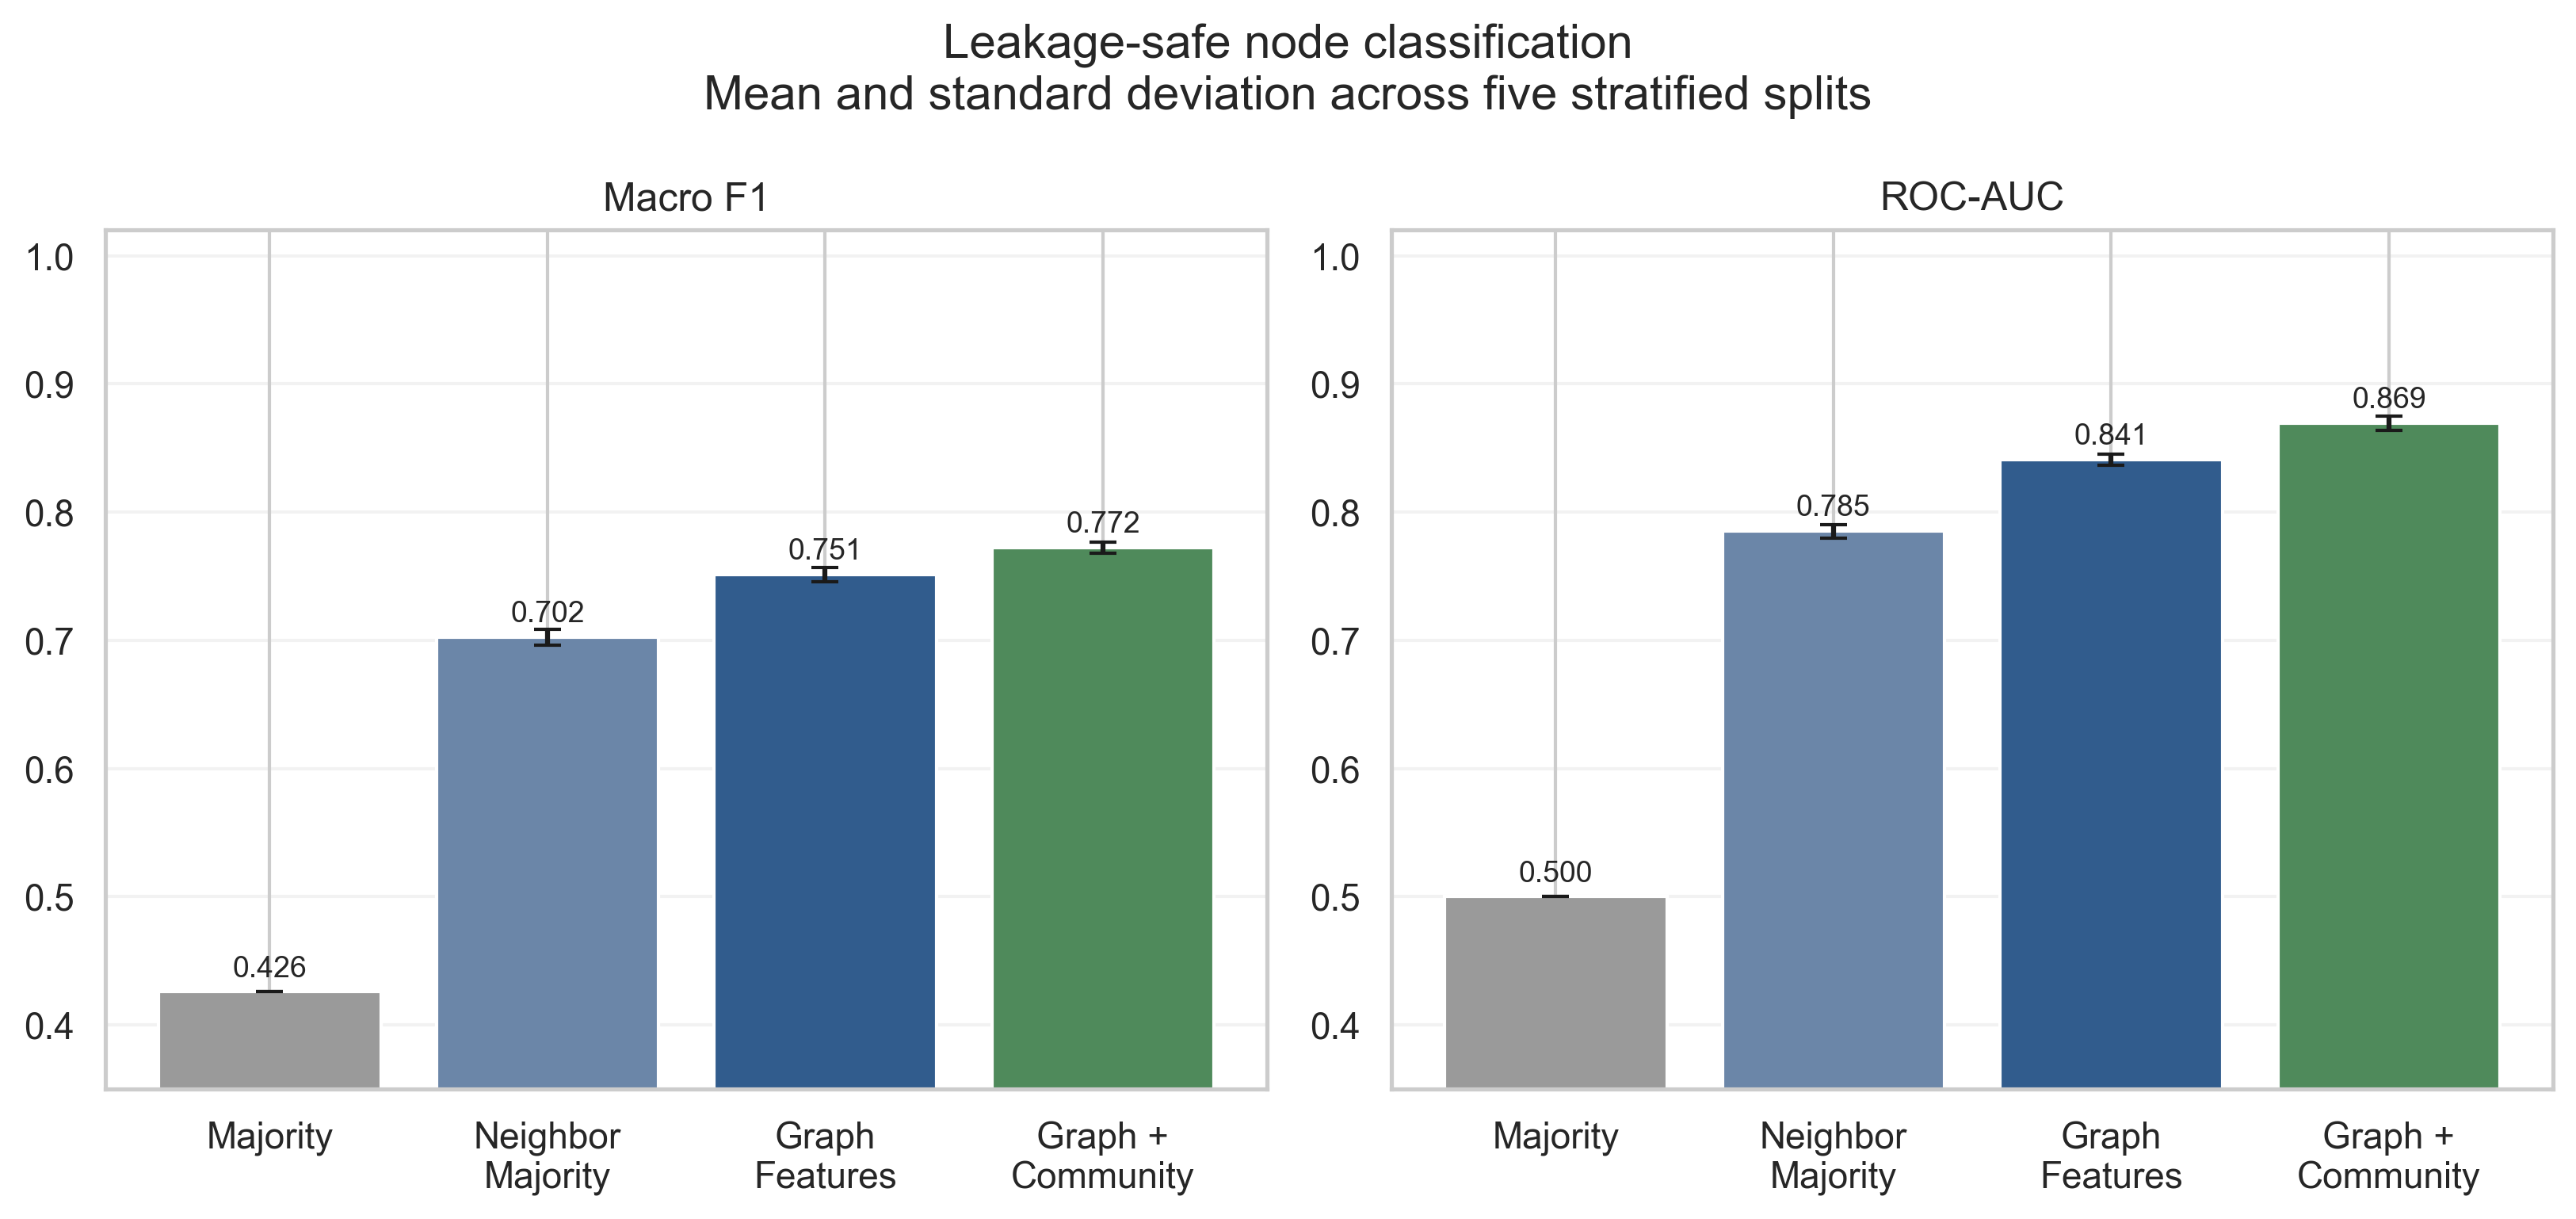

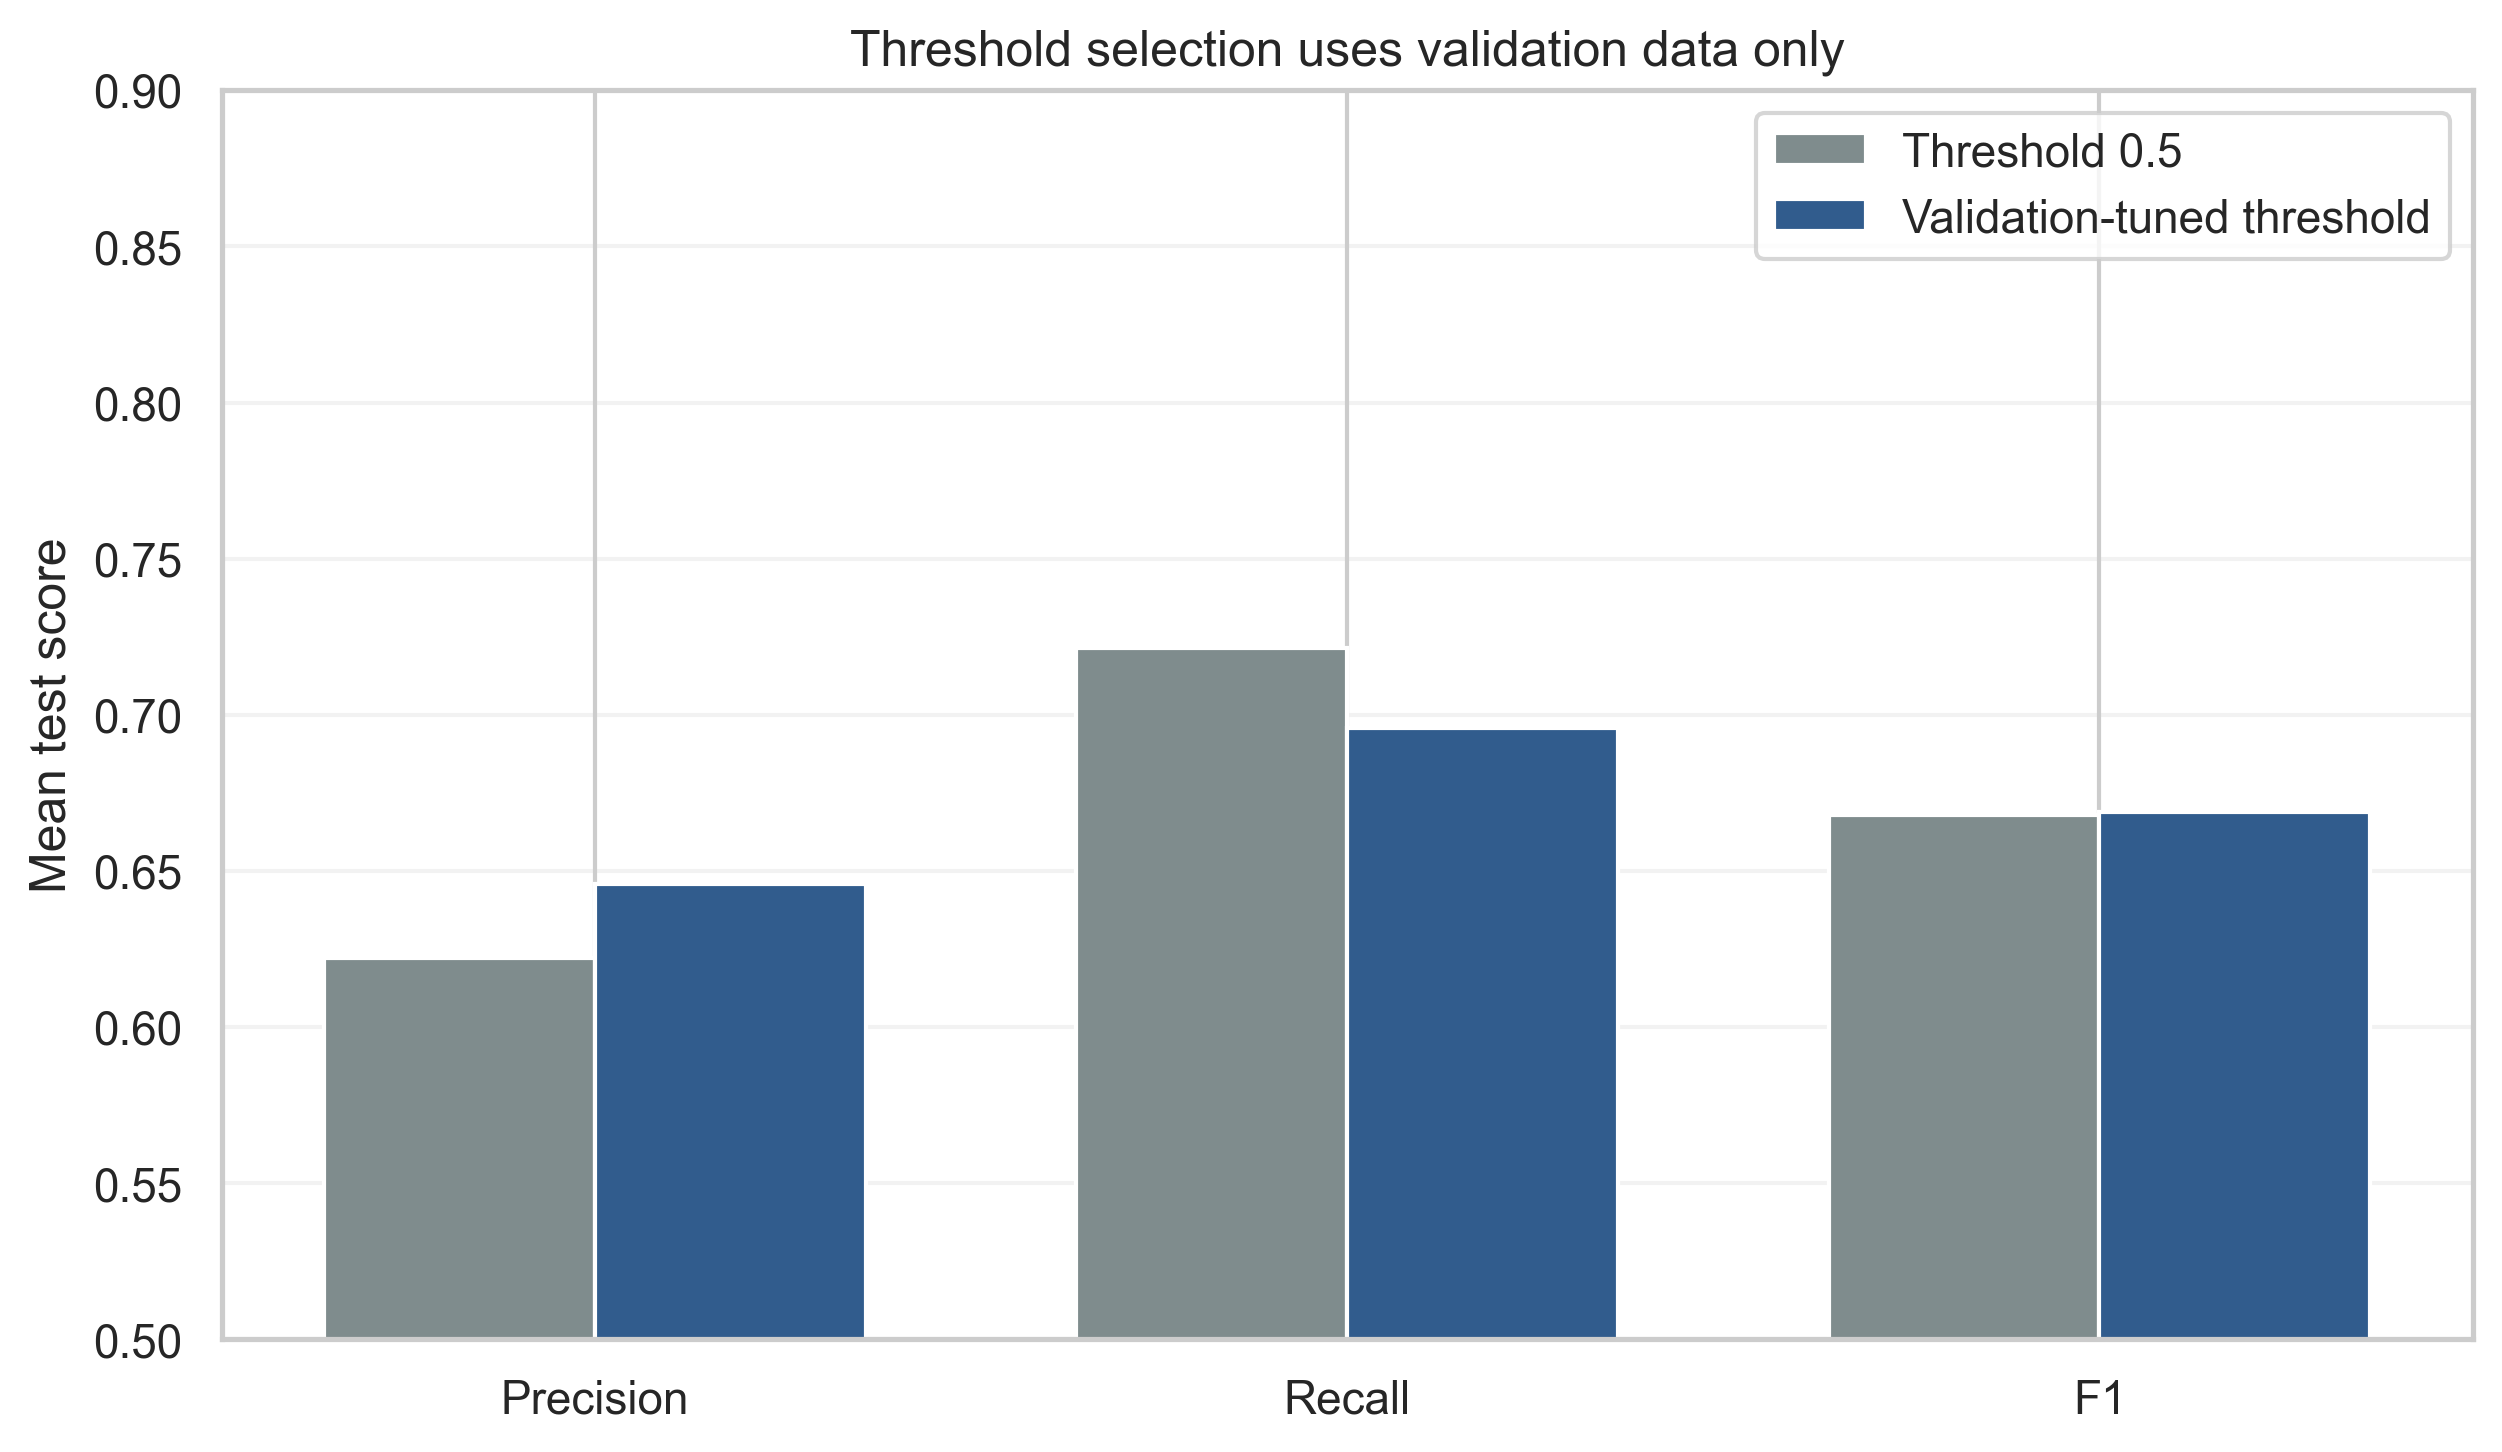

In [11]:
classification = pd.read_csv(ROOT / "outputs/tables/classification_summary.csv")
thresholds = pd.read_csv(ROOT / "outputs/tables/threshold_tuning_summary.csv")
display(classification.sort_values("roc_auc_mean", ascending=False).round(4))
display(thresholds.round(4))
display(Image(filename=str(ROOT / "outputs/figures/classification_comparison.png")))
display(Image(filename=str(ROOT / "outputs/figures/threshold_tradeoff.png")))


Graph and community features classify developer field well, with mean ROC-AUC near 0.869 for the strongest handcrafted model. Threshold tuning changes the precision–recall trade-off but is selected on validation data only; ROC-AUC is unaffected by the threshold.

## Error analysis only

Degree groups and community purity are used after prediction to understand errors. Community purity is never included in the predictive feature matrix.


,degree_group,count,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1
0,degree_0_2,2877,0.7459,0.7321,0.6235,0.6863,0.6534,0.7264,0.7485
1,degree_3_5,2784,0.7956,0.7816,0.6287,0.7476,0.6830,0.7661,0.8002
2,degree_6_10,2207,0.8337,0.8064,0.6434,0.7518,0.6934,0.7897,0.8378
3,degree_11_30,2367,0.8606,0.7997,0.6008,0.7037,0.6482,0.7806,0.8647
4,degree_31_plus,1075,0.9060,0.8199,0.5436,0.7105,0.6160,0.7812,0.9114


,purity_group,count,errors,error_rate
0,mixed_lt_0.70,35,16,0.4571
1,medium_0.70_0.85,6951,1757,0.2528
2,pure_0.85_plus,4324,325,0.0752


,error_type,count,ratio
0,Correct Web,7110,0.628647
1,Correct ML,2102,0.185853
2,Web -> ML,1278,0.112997
3,ML -> Web,820,0.072502


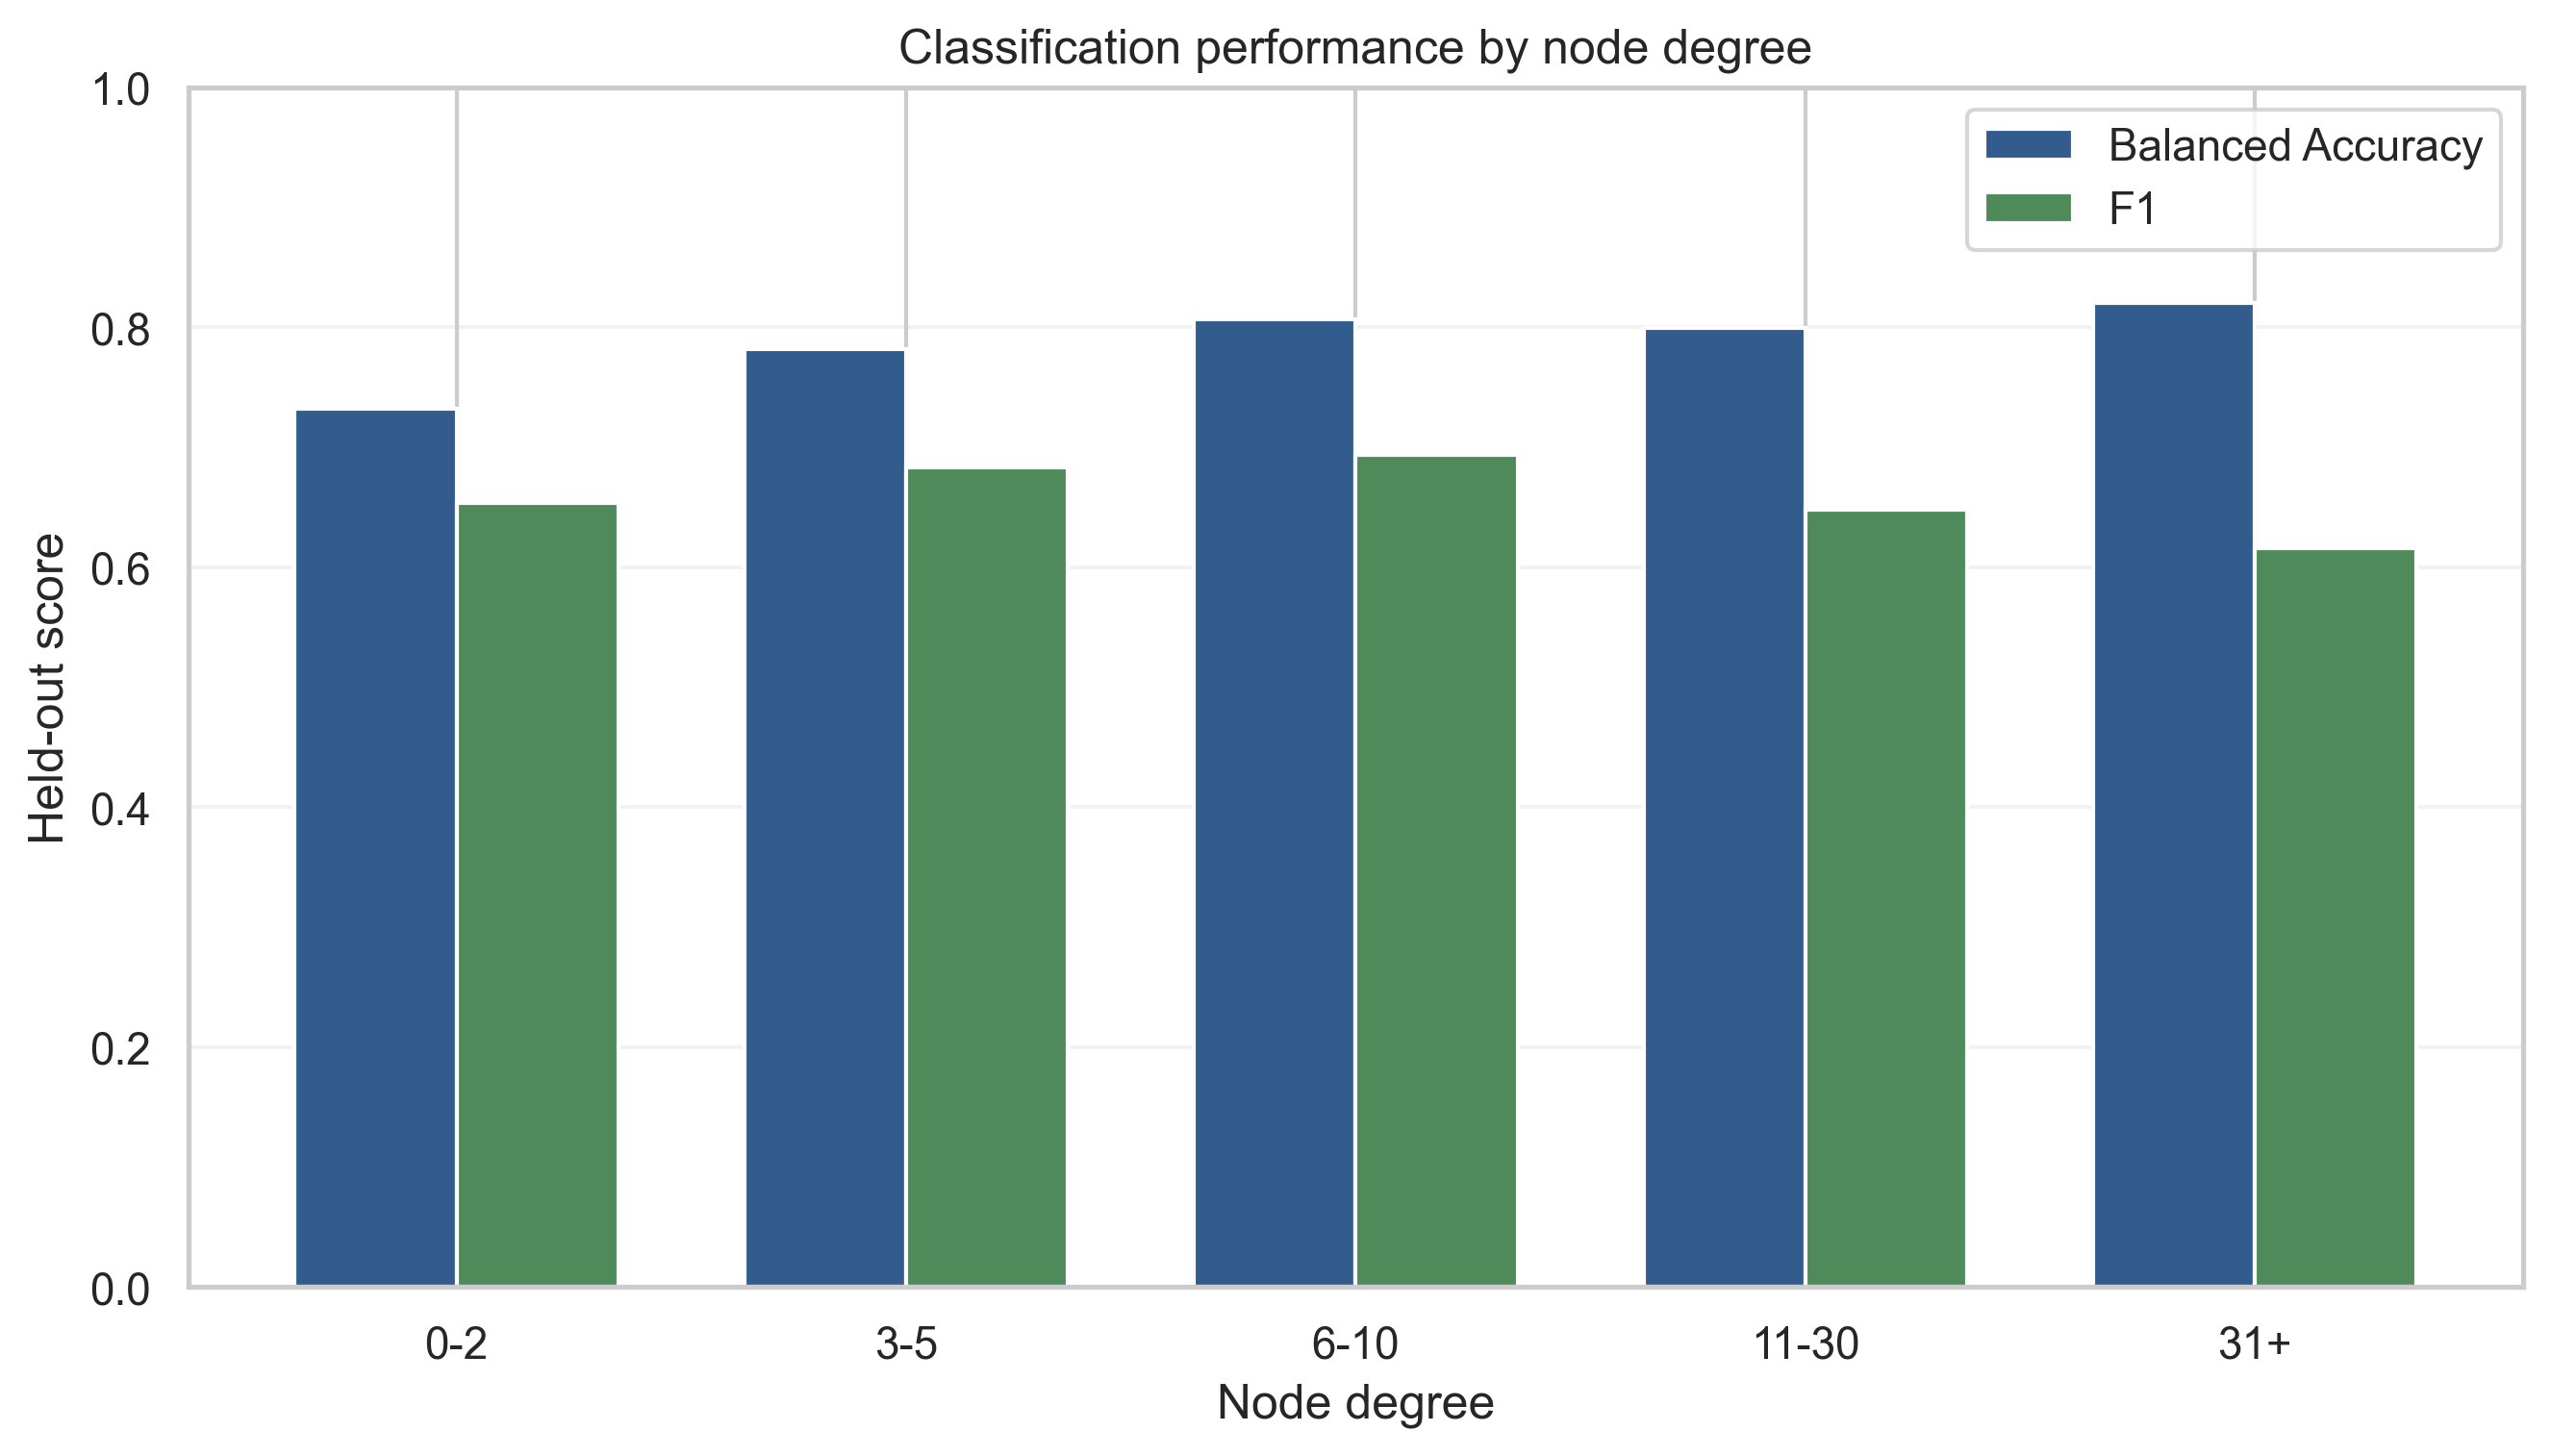

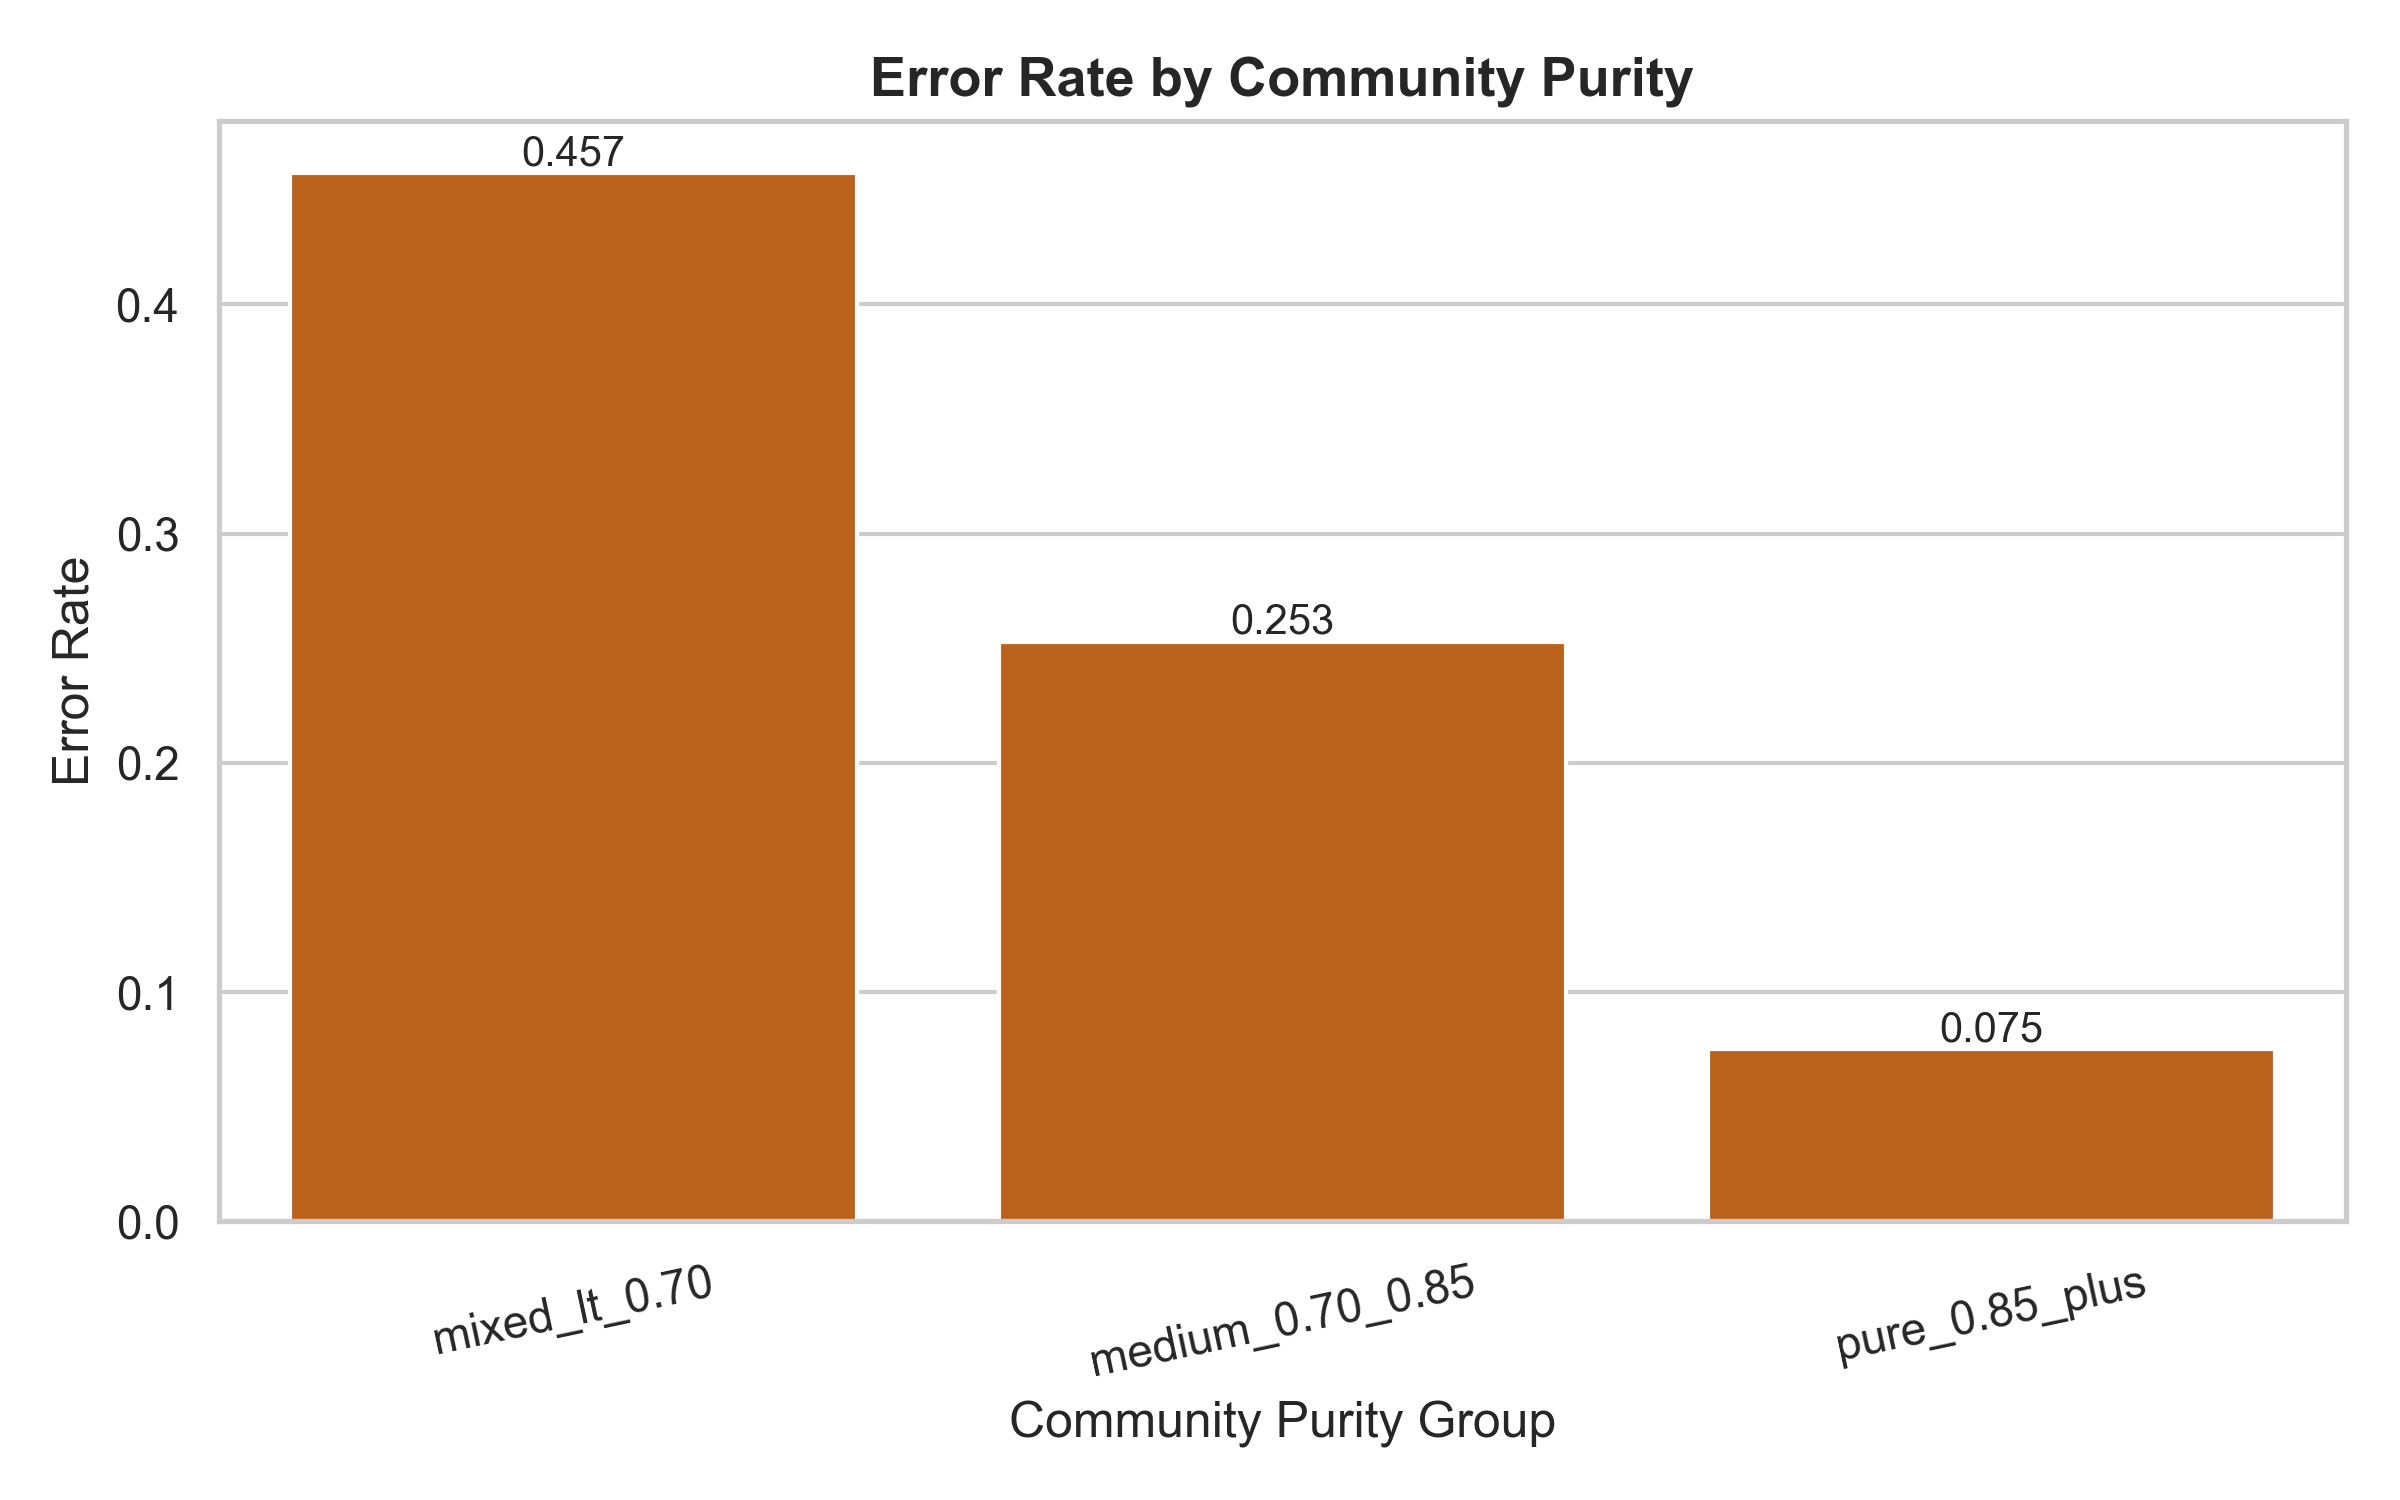

In [12]:
degree_errors = pd.read_csv(ROOT / "outputs/tables/classification_by_degree_group.csv")
purity_errors = pd.read_csv(ROOT / "outputs/tables/classification_by_community_purity.csv")
error_types = pd.read_csv(ROOT / "outputs/tables/classification_error_types.csv")
display(degree_errors.round(4))
display(purity_errors.round(4))
display(error_types)
display(Image(filename=str(ROOT / "outputs/figures/classification_by_degree_group.png")))
display(Image(filename=str(ROOT / "outputs/figures/community_purity_error_analysis.png")))


Low-degree nodes provide less structural evidence, making them harder to classify reliably. Mixed communities are also harder, but that conclusion is diagnostic rather than a source of predictive information.

## Summary

This Notebook evaluated field classification over five fixed stratified 70/30 splits using a majority baseline, neighbor majority, graph-feature logistic regression, and graph-plus-community logistic regression. Feature construction, scaling, community label ratios, and validation-only threshold selection used training labels only; the test partitions contained 11,310 nodes with no train/test overlap.

Graph plus community features gave the strongest handcrafted result, with mean ROC-AUC 0.8694, Macro-F1 0.7724, and accuracy 0.8169. Graph-only logistic regression reached ROC-AUC 0.8410, while Neighbor Majority reached 0.7851 and combined high ML precision (0.8312) with low recall (0.3747). The majority baseline achieved ROC-AUC 0.5000.

Validation-selected thresholds averaged 0.55 instead of 0.50. Tuning increased mean accuracy from 0.8148 to 0.8221, precision from 0.6221 to 0.6458, and Macro-F1 from 0.7698 to 0.7736, while recall fell from 0.7213 to 0.6958; ROC-AUC remained 0.8654 because thresholding does not change ranking.

Error analysis showed that accuracy rose from 0.7459 for degree 0?2 nodes to 0.9060 for degree 31+, and error rates fell from 45.71% in the small mixed-community group to 7.52% in communities with purity at least 0.85. These held-out results show substantial but imperfect predictive information in network structure and supply the baseline tables used by the representation comparisons.
